# torchvision - affine transform (image) 

https://pytorch.org/vision/main/generated/torchvision.transforms.functional.affine.html

In [1]:
image_path = '/home/dev/pose/data/coco/images/train2017/000000537548.jpg'
bbox = [267, 104, 229, 320]

In [2]:
from PIL import Image
from IPython.display import display

In [3]:
%matplotlib inline
from torchvision.io import read_image
from matplotlib import pyplot as plt
from torchvision.transforms.v2 import ToPILImage

to_pil = ToPILImage()

COLOR_MAGENTA = (255, 0, 255) # RGB
COLOR_CYAN = (0, 255, 255) # RGB
COLOR_YELLOW = (255, 255, 0) # RGB

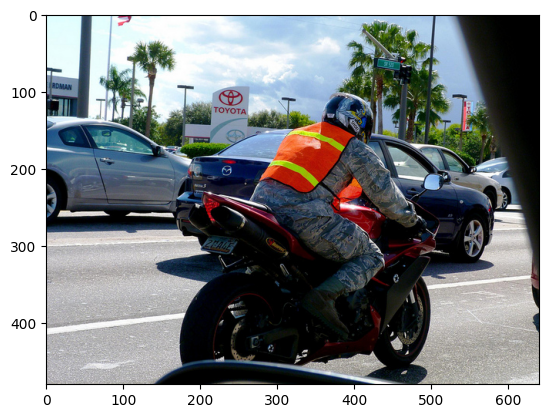

In [4]:
img = read_image(image_path)
plt_img = to_pil(img)

plt.imshow(plt_img)
plt.show()

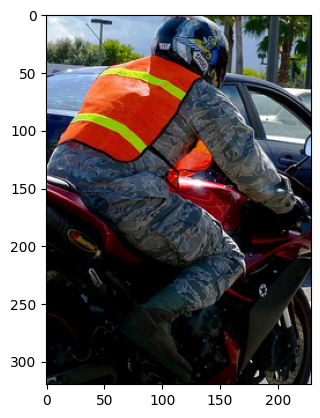

In [5]:
x, y, w, h = bbox
cropped_img = img[:,y:y+h,x:x+w]

plt_cropped_img = to_pil(cropped_img)
plt.imshow(plt_cropped_img)
plt.show()

In [6]:
from torchvision.transforms.v2.functional import affine
from torchvision.transforms.v2 import InterpolationMode

https://pytorch.org/vision/main/generated/torchvision.transforms.functional.affine.html

Interpolation 방식이 2가지가 있다. `BILINEAR`, `NEAREST`
전반적으로 테스트 해봤을땐 `BILINEAR` 결과가 확실히 좋았다.

Bilinear interpolation 관련 참고 자료
- https://blog.naver.com/aorigin/220947541918
- https://darkpgmr.tistory.com/117

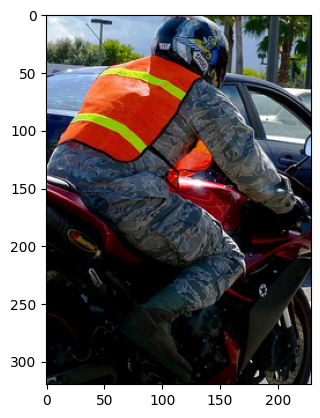

In [7]:
angle = 00          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
# interpolation = InterpolationMode.NEAREST
interpolation = InterpolationMode.BILINEAR
fill = None
center = None

transformed_img = affine(cropped_img, angle, translate, scale, shear, interpolation, fill, center)
transformed_plt_img = to_pil(transformed_img)
plt.imshow(transformed_plt_img)
plt.show()

## 회전

BILINEAR(좌측)가 결과가 좋다.

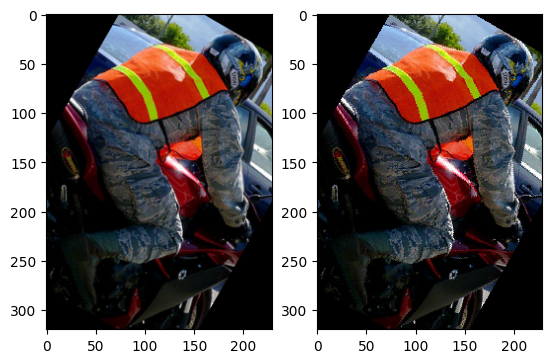

In [8]:
angle = 30

interpolation = InterpolationMode.BILINEAR
img1 = affine(cropped_img, angle, translate, scale, shear, interpolation, fill, center)
img1 = to_pil(img1)

interpolation = InterpolationMode.NEAREST
img2 = affine(cropped_img, angle, translate, scale, shear, interpolation, fill, center)
img2 = to_pil(img2)

f, axarr = plt.subplots(1,2)
axarr[0].imshow(img1)
axarr[1].imshow(img2)
plt.show()

확대해보면, 확실히 bilinear(좌측)쪽이 결과가 좋은걸 알 수 있다.

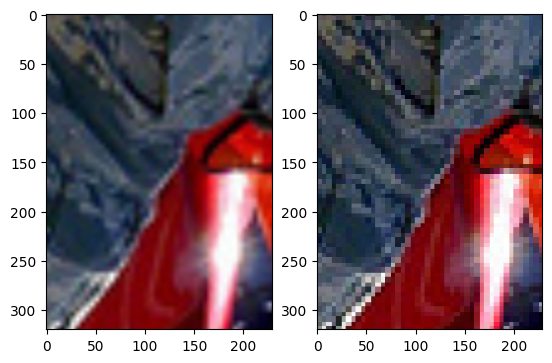

In [9]:
angle = 90
scale = 5

interpolation = InterpolationMode.BILINEAR
img1 = affine(cropped_img, angle, translate, scale, shear, interpolation, fill, center)
img1 = to_pil(img1)

interpolation = InterpolationMode.NEAREST
img2 = affine(cropped_img, angle, translate, scale, shear, interpolation, fill, center)
img2 = to_pil(img2)

f, axarr = plt.subplots(1,2)
axarr[0].imshow(img1)
axarr[1].imshow(img2)
plt.show()

# torchvision - resize
https://pytorch.org/vision/main/generated/torchvision.transforms.Resize.html

In [10]:
# reset values

angle = 00          # angle in degree: -180 to 180
translate = [0, 0]  # horizontal and vertical translations
scale = 1.0         # overall scale
shear = [0, 0]
# interpolation = InterpolationMode.NEAREST
interpolation = InterpolationMode.BILINEAR
fill = None
center = None

In [11]:
from torchvision.transforms.v2 import Resize

In [12]:
cropped_img.shape

torch.Size([3, 320, 229])

## 사이즈 줄이기

확실히 BILINEAR(좌측)쪽이 결과가 좋다.

In [13]:
s = 0.5  # scale

bl_resizer = Resize(size=[int(320*s), int(229*s)], interpolation=InterpolationMode.BILINEAR)
nr_resizer = Resize(size=[int(320*s), int(229*s)], interpolation=InterpolationMode.NEAREST)

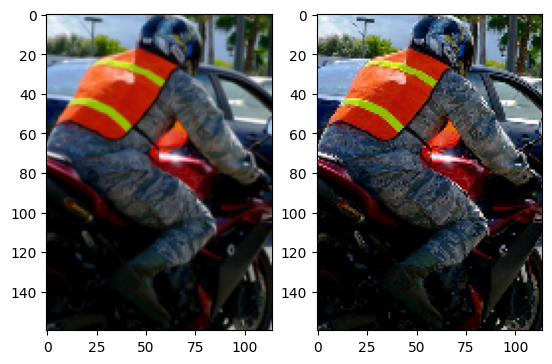

In [14]:
img1 = bl_resizer(cropped_img)
img2 = nr_resizer(cropped_img)

img11 = to_pil(img1)
img22 = to_pil(img2)

f, axarr = plt.subplots(1,2)
axarr[0].imshow(img11)
axarr[1].imshow(img22)
plt.show()

## 사이즈 키우기

키울땐 별 차이 안 느껴지네

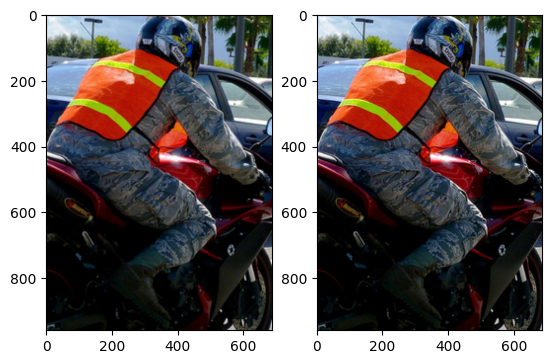

In [15]:
s = 3  # scale

bl_resizer = Resize(size=[int(320*s), int(229*s)], interpolation=InterpolationMode.BILINEAR)
nr_resizer = Resize(size=[int(320*s), int(229*s)], interpolation=InterpolationMode.NEAREST)

img1 = bl_resizer(cropped_img)
img2 = nr_resizer(cropped_img)

img11 = to_pil(img1)
img22 = to_pil(img2)

f, axarr = plt.subplots(1,2)
axarr[0].imshow(img11)
axarr[1].imshow(img22)
plt.show()